In [1]:
import os
import numpy as np
import pandas as pd
import uproot as ur

import sys
utils_path = '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/'
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from jupyter_utils import *

from matplotlib import pyplot as plt
from IPython.display import Image
pd.set_option('display.max_columns', None) # to see all columns of df.head()
pd.set_option('display.max_rows', None)

from matplotlib.patches import PathPatch
from matplotlib.path import Path
from matplotlib.ticker import MaxNLocator, NullFormatter

# Lauren's colors
L_colors = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black']
L_linestyles = ['solid', 'dashed']
L_markers = ['s', '^', 'v', 'd', 'P']

In [ ]:
# closure test? i.e. there is truth pythia data somewhere to compare to
closure = True

JETPT_BINS = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500], dtype=np.float64)

RL_NBINS = 24 #25
RL_MIN, RL_MAX = 0.01, 1.0
RL_BINS = np.logspace(np.log10(RL_MIN), np.log10(RL_MAX), RL_NBINS + 1)

W_NBINS = 20 #30 #100
W_MIN, W_MAX = 0.0, 0.3 #1.0 #0.3
W_BINS = np.logspace(-5,-0.5,W_NBINS+1)


# define binnings
n_bins_true = [9, 25, 20] # jet pt, RL, weight #[20, 12, 6] # [20, 22, 7] # WARNING RooUnfold seg faults if too many bins used
RL_bins = RL_BINS
# binning = [np.logspace(-5,0,n_bins_true[0]+1), \
#             np.logspace(-2.299,0,n_bins_true[1]+1), \
#             np.array([5, 10, 20, 40, 60, 80, 100, 150]).astype(float) ]
binning = [JETPT_BINS, \
           RL_bins, \
           W_BINS ]
print(binning)
bincenters = [ get_lin_bincenters(binning[0]), get_log_bincenters(binning[1]), get_log_bincenters(binning[2]) ]
binwidths = [ get_binwidths(a) for a in binning ]

n_bins = [9, 25, 20] #n_bins = [20, 22, 6]
# binning_reco = [np.logspace(-5,0,n_bins[0]+1), \
#             np.logspace(-2.299,0,n_bins[1]+1), \
#             np.array([10, 20, 40, 60, 80, 100, 150]).astype(float) ]
binning_reco = [JETPT_BINS, \
                RL_bins, \
                W_BINS ]
bincenters_reco = [ get_log_bincenters(binning_reco[0]), get_log_bincenters(binning_reco[1]), get_lin_bincenters(binning_reco[2]) ]
binwidths_reco = [ np.array(get_binwidths(a)) for a in binning_reco ]

xlabels = [ r"jet $p_{T}$", r"$R_{L}$", "energy weight" ]

n_iter = 5 #3

[array([ 10.,  20.,  40.,  60.,  80., 100., 120., 150., 200., 500.]), array([0.01      , 0.01202264, 0.0144544 , 0.01737801, 0.02089296,
       0.02511886, 0.03019952, 0.03630781, 0.04365158, 0.05248075,
       0.06309573, 0.07585776, 0.09120108, 0.10964782, 0.13182567,
       0.15848932, 0.19054607, 0.22908677, 0.27542287, 0.33113112,
       0.39810717, 0.47863009, 0.57543994, 0.69183097, 0.83176377,
       1.        ]), array([1.00000000e-05, 1.67880402e-05, 2.81838293e-05, 4.73151259e-05,
       7.94328235e-05, 1.33352143e-04, 2.23872114e-04, 3.75837404e-04,
       6.30957344e-04, 1.05925373e-03, 1.77827941e-03, 2.98538262e-03,
       5.01187234e-03, 8.41395142e-03, 1.41253754e-02, 2.37137371e-02,
       3.98107171e-02, 6.68343918e-02, 1.12201845e-01, 1.88364909e-01,
       3.16227766e-01])]


## Define files and histograms

In [ ]:
# file defs, hist imports

f_unfolded = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded.root")
f_unfolded1D = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D.root")
f_preunfold_rm = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/60403841/response_groomed_forunfolding_merged.root")
# f_preunfold_data = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/data/60320414/AnalysisResultsMerged_groomedbins.root")
f_preunfold_data = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/data/60320414/AnalysisResultsMerged_groomedbins.root")

f_closure_tests_1D = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D_tests.root")
f_closure_tests = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded_tests.root")



In [ ]:
labels = [ "AA", "AB", "BB", "rad" ]

# MC, true [theta0_G]
h1_gen_all = f_preunfold_rm["jet_all_gen_eff_den_groomed"] #"gen1D"]
h3_gen_all = {}

# MC, reco
h1_reco_all = f_preunfold_rm["jet_all_rec_pur_den_groomed"] #"reco1D"]
h3_reco_all = {}

# MC, true [theta0_G]
h1_gen_matched = f_preunfold_rm["jet_match_gen_eff_num_groomed"] #"gen1D"]
h3_gen_matched = {}

# MC, reco
h1_reco_matched = f_preunfold_rm["jet_match_rec_pur_num_groomed"] #"reco1D"]
h3_reco_matched = {}

# Data, reco (raw)
h1_raw = f_preunfold_data["groomed_sd0.1_jet_pt_raw1D"]
h3_raw = {}


for lab in labels:
    h3_gen_all[lab] = f_preunfold_rm[f"groomed_{lab}_gen_all"]
    h3_reco_all[lab] = f_preunfold_rm[f"groomed_{lab}_reco_all"]
    h3_gen_matched[lab] = f_preunfold_rm[f"groomed_{lab}_gen_matched"]
    h3_reco_matched[lab] = f_preunfold_rm[f"groomed_{lab}_reco_matched"]
    h3_raw[lab] = f_preunfold_data[f"{lab}_sd0.1_raw"]


# # MC, original RM
# # matrix = f_unfolded["matrix_{}".format(lab)].values()
# matrix1D = f_unfolded["matrix1D"].values()
# # matrix1D = f_preunfold_rm2["resp_jetpt_groomed"].values()



### Refolding test ###
# Data, unfolded
h1_unfolded = []
h3_unfolded = {}
for i in range(1,n_iter+1):
    h1_unfolded.append(f_closure_tests_1D["refolding_closure/Baysian_Unfolded1Diter{}".format(i)])

# Data, refolded
h1_refolded = []
h3_refolded = {}
for i in range(1, n_iter+1):
    h1_refolded.append(f_closure_tests_1D["refolding_closure/Baysian_Refolded1Diter{}".format(i)])

for lab in labels:
    for i in range(1, n_iter+1):
        if i == 1:
            h3_unfolded[lab] = []
            h3_refolded[lab] = []
        h3_unfolded[lab].append(f_closure_tests[f"refolding_closure/Bayesian_Unfolded_{lab}_iter{i}"])
        h3_refolded[lab].append(f_closure_tests[f"refolding_closure/Bayesian_Refolded_{lab}_iter{i}"])

# # Data, true [theta_unknown_G]
# if closure:
#     h1_true = f_preunfold_rm["jet_match_gen_eff_num_groomed"] #"gen1D"]



## Define Functinos

In [42]:
def plot_closure_test_axes_singleplot(n_iter, bincenters, binning, binwidths, y_lines, y_points, y_points_err, 
                                      L_colors, L_markers, label_lines, label_points,
                                      unfolding=True, extralabel=""):

    fig, axs = plt.subplots(2, 3, figsize=(18, 8), sharex='col',
                            gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
    xlabels = [r"jet $p_{T}$", r"$R_{L}$", "energy weight"]

    for i in range(3):  # observable / axis index

        # ---------------- TOP PANELS - DISTRIBUTIONS ----------------
        ax = axs[0, i]
        ax.stairs(y_lines[i], binning[i], color='black', lw=1.8, label=label_lines)

        for it in range(n_iter):
            ax.errorbar(bincenters[i], y_points[it][i], yerr=y_points_err[it][i],
                        fmt=L_markers[it], color=L_colors[it], capsize=5, capthick=2,
                        linestyle="None", zorder=3, # markerfacecolor='none'
                        label=rf"{label_points}, $n_{{\mathrm{{iter}}}}$ = {it+1}") 
        
        #if i in [1, 2]:
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_ylabel("Counts")
        ax.legend(frameon=False, fontsize=9)
        ax.text(0.1, 0.1, extralabel, transform=ax.transAxes, fontsize=10,
                verticalalignment="top", horizontalalignment="left")

        # ---------------- BOTTOM PANELS - RATIO ----------------
        ax = axs[1, i]
        ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
        ax.axhline(1.0, color='gray', linestyle='--', zorder=1)

        for it in range(n_iter):
            yvals_ratio = safe_divide(y_points[it][i], y_lines[i], filler=1)
            ax.scatter(bincenters[i], yvals_ratio, color=L_colors[it], marker=L_markers[it],
                       lw=1.5, zorder=2, label=rf"$n_{{\mathrm{{iter}}}}$ = {it+1}")

            yerrs_ratio = safe_divide(y_points_err[it][i], y_points[it][i])
            ax.fill_between(bincenters[i], (yvals_ratio-yerrs_ratio), (yvals_ratio+yerrs_ratio), alpha=0.4, edgecolor=L_colors[it], facecolor=L_colors[it], linewidth=0)
                    

        ax.set_xlabel(xlabels[i])
        ax.set_ylabel("Unfolded / Truth" if unfolding else "Refolded / Raw")
        ax.legend(frameon=False, fontsize=9, ncol=2)

    fig.tight_layout()
    fig.subplots_adjust(hspace=0)
    plt.show()
    

In [ ]:
def _njets_in_ptbins(h1, pt_edges):
    """Sum a 1D jet-pT histogram into the given pT bins (handles finer input binning).
    Returns (N_jets, N_jets_err) with one entry per pT bin."""
    vals = np.asarray(h1.values(), dtype=np.float64)
    errs = np.asarray(h1.errors(), dtype=np.float64)
    h_edges = np.asarray(h1.axis().edges(), dtype=np.float64)
    centers = 0.5 * (h_edges[:-1] + h_edges[1:])

    N = np.zeros(len(pt_edges) - 1)
    N_err = np.zeros(len(pt_edges) - 1)
    for k in range(len(pt_edges) - 1):
        mask = (centers >= pt_edges[k]) & (centers < pt_edges[k + 1])
        N[k] = vals[mask].sum()
        N_err[k] = np.sqrt((errs[mask] ** 2).sum())
    return N, N_err


def _eec_from_pt_slice(vals_cut, errs_cut, w_centers, rl_widths, N, N_err=None):
    """Weighted, normalized EEC from a pT-sliced (RL x weight) 2D array.
    EEC(RL) = sum_w [ U(RL, w) * w ] / (N_jets * dRL)"""
    vals_cut = np.asarray(vals_cut, dtype=np.float64)
    errs_cut = np.asarray(errs_cut, dtype=np.float64)
    w_centers = np.asarray(w_centers, dtype=np.float64)

    eec = (vals_cut @ w_centers) / rl_widths
    eec_err = np.sqrt((errs_cut ** 2) @ (w_centers ** 2)) / rl_widths

    if N <= 0:
        return np.zeros_like(eec), np.zeros_like(eec_err)

    if N_err is not None:
        eec_err = get_ratio_err(eec, N, eec_err, N_err)   # propagate error on N_jets
    else:
        eec_err = eec_err / N
    eec = eec / N
    return eec, eec_err

def plot_closure_test_fullEEC(lab, h3_raw_lab, h3_refolded_lab, h1_raw, h1_refolded,
                              bincenters, binning, binwidths,
                              L_colors, L_markers,
                              pt_bin_indices=range(1, 8), nrows=2, ncols=4,
                              propagate_refolded_Njet_err=True,
                              ratio_ylim=(0.8, 1.2), eec_ylim=None, logy=False,
                              extralabel=""):
    """
    Refolding closure test on the full EEC: one panel (distribution + ratio) per jet pT bin,
    all panels connected with shared x and y axes. Legend goes in the first empty grid slot.
    """
    pt_edges = binning[0]
    rl_edges = binning[1]
    rl_centers = bincenters[1]
    rl_widths = np.asarray(binwidths[1], dtype=np.float64)
    w_centers = bincenters[2]

    pt_bin_indices = list(pt_bin_indices)
    n_used = len(pt_bin_indices)
    if n_used > nrows * ncols:
        raise ValueError(f"{n_used} pT bins don't fit on a {nrows}x{ncols} grid")

    # jet counts per pT bin
    N_raw, N_raw_err = _njets_in_ptbins(h1_raw, pt_edges)
    N_ref, N_ref_err = zip(*[_njets_in_ptbins(h1_refolded[it], pt_edges) for it in range(n_iter)])

    # pull values/errors once
    raw_vals, raw_errs = h3_raw_lab.values(), h3_raw_lab.errors()
    ref_vals = [h.values() for h in h3_refolded_lab[:n_iter]]
    ref_errs = [h.errors() for h in h3_refolded_lab[:n_iter]]

    # one gridspec: rows alternate (EEC, ratio), no spacing anywhere
    fig = plt.figure(figsize=(4.2 * ncols, 4.5 * nrows))
    gs = fig.add_gridspec(2 * nrows, ncols, height_ratios=[2, 1] * nrows, hspace=0, wspace=0)

    ax_top_ref, ax_bot_ref = None, None
    legend_handles, legend_labels = None, None

    for k, i in enumerate(pt_bin_indices):
        row, col = divmod(k, ncols)

        ax_top = fig.add_subplot(gs[2 * row, col], sharex=ax_top_ref, sharey=ax_top_ref)
        ax_bot = fig.add_subplot(gs[2 * row + 1, col],
                                 sharex=ax_top_ref if ax_top_ref is not None else ax_top,
                                 sharey=ax_bot_ref)
        if ax_top_ref is None:
            ax_top_ref, ax_bot_ref = ax_top, ax_bot

        slice_on_pt = lambda a: xslice_th3d(a, i, i + 1)

        # ---------------- raw EEC ----------------
        raw_EEC, raw_EEC_err = _eec_from_pt_slice(slice_on_pt(raw_vals), slice_on_pt(raw_errs),
                                                  w_centers, rl_widths, N_raw[i])

        # ---------------- refolded EEC per iteration ----------------
        ref_EEC, ref_EEC_err = [], []
        for it in range(n_iter):
            e, ee = _eec_from_pt_slice(slice_on_pt(ref_vals[it]), slice_on_pt(ref_errs[it]),
                                       w_centers, rl_widths, N_ref[it][i],
                                       N_ref_err[it][i] if propagate_refolded_Njet_err else None)
            ref_EEC.append(e)
            ref_EEC_err.append(ee)

        # ---------------- TOP: distributions ----------------
        ax_top.stairs(raw_EEC, rl_edges, color='black', lw=1.8, label="Raw data")
        ax_top.stairs(raw_EEC + raw_EEC_err, rl_edges, baseline=raw_EEC - raw_EEC_err,
                      fill=True, color='gray', alpha=0.3, lw=0, label="raw stat. unc.")
        for it in range(n_iter):
            ax_top.errorbar(rl_centers, ref_EEC[it], yerr=ref_EEC_err[it],
                            fmt=L_markers[it], color=L_colors[it], capsize=3, capthick=1.2,
                            markersize=5, linestyle="None", zorder=3,
                            label=rf"Refolded, $n_{{\mathrm{{iter}}}}$ = {it+1}")
        ax_top.text(0.05, 0.95, rf"jet $p_{{T}}$ = {int(pt_edges[i])}-{int(pt_edges[i+1])} GeV",
                    transform=ax_top.transAxes, fontsize=10,
                    verticalalignment="top", horizontalalignment="left")

        # ---------------- BOTTOM: ratio refolded / raw ----------------
        ax_bot.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
        ax_bot.axhline(1.0, color='gray', linestyle='--', zorder=1)
        for it in range(n_iter):
            ratio = safe_divide(ref_EEC[it], raw_EEC, filler=1)
            ax_bot.scatter(rl_centers, ratio, color=L_colors[it], marker=L_markers[it],
                           s=20, zorder=2)

            yerrs_ratio = safe_divide(ref_EEC_err[it], ref_EEC[it])
            ax_bot.fill_between(rl_centers, (ratio-yerrs_ratio), (ratio+yerrs_ratio), alpha=0.4, edgecolor=L_colors[it], facecolor=L_colors[it], linewidth=0)
                        

        # ---------------- tick label / axis label visibility ----------------
        ax_top.tick_params(labelbottom=False, direction='in', which='both', top=True, right=True)
        ax_bot.tick_params(direction='in', which='both', top=True, right=True)

        if col == 0:
            ax_top.set_ylabel(r"$\frac{1}{N_{\mathrm{jet}}}\frac{d\Sigma_{\mathrm{EEC}}}{dR_{L}}$")
            ax_bot.set_ylabel("Refolded / Raw")
        else:
            ax_top.tick_params(labelleft=False)
            ax_bot.tick_params(labelleft=False)

        has_panel_below = (k + ncols) < n_used
        if has_panel_below:
            ax_bot.tick_params(labelbottom=False)
        else:
            ax_bot.set_xlabel(r"$R_{L}$")

        # grab legend entries from the first panel only
        if legend_handles is None:
            h_top, l_top = ax_top.get_legend_handles_labels()
            h_bot, l_bot = ax_bot.get_legend_handles_labels()
            legend_handles, legend_labels = h_top + h_bot, l_top + l_bot

    # ---------------- shared axis settings (apply to all panels) ----------------
    ax_top_ref.set_xscale('log')
    ax_top_ref.set_xlim(rl_edges[0], rl_edges[-1])
    # explicit ticks away from the panel edges so labels don't collide between columns
    xt = [0.02, 0.05, 0.1, 0.2, 0.5]
    ax_top_ref.set_xticks(xt, labels=[str(x) for x in xt])
    ax_top_ref.xaxis.set_minor_formatter(NullFormatter())

    if logy:
        ax_top_ref.set_yscale('log')
    else:
        # prune bottom tick so it doesn't collide with the ratio panel's top label
        ax_top_ref.yaxis.set_major_locator(MaxNLocator(nbins=5, prune='lower'))
    if eec_ylim is not None:
        ax_top_ref.set_ylim(*eec_ylim)

    ax_bot_ref.set_ylim(*ratio_ylim)
    ax_bot_ref.yaxis.set_major_locator(MaxNLocator(nbins=4, prune='both'))

    # ---------------- shared legend in the first empty slot ----------------
    title = f"{lab} pairs" + (f"\n{extralabel}" if extralabel else "")
    if n_used < nrows * ncols:
        row, col = divmod(n_used, ncols)
        ax_leg = fig.add_subplot(gs[2 * row:2 * row + 2, col])
        ax_leg.axis('off')
        ax_leg.legend(legend_handles, legend_labels, loc='center', frameon=False,
                      fontsize=11, title=title, title_fontsize=12)
    else:
        fig.legend(legend_handles, legend_labels, loc='upper center',
                   ncol=len(legend_labels), frameon=False, fontsize=10, title=title)

    plt.show()
    return fig


In [ ]:
def plot_refolding_iteration_deltas(lab, h3_refolded_lab, h1_refolded,
                                    bincenters, binning, binwidths,
                                    L_colors, L_markers,
                                    pt_bin_indices=range(1, 8), nrows=2, ncols=4,
                                    propagate_refolded_Njet_err=True,
                                    delta_ylim=(-0.05, 0.05), extralabel=""):
    """
    Plots the relative delta between consecutive refolding iterations for the full weighted,
    normalized EEC across jet pT bins:
    Delta_{iter k} = (Refolded_{iter k} - Refolded_{iter k-1}) / Refolded_{iter k-1}
    with error bars.
    """
    pt_edges = binning[0]
    rl_edges = binning[1]
    rl_centers = bincenters[1]
    rl_widths = np.asarray(binwidths[1], dtype=np.float64)
    w_centers = bincenters[2]

    pt_bin_indices = list(pt_bin_indices)
    n_used = len(pt_bin_indices)
    if n_used > nrows * ncols:
        raise ValueError(f"{n_used} pT bins don't fit on a {nrows}x{ncols} grid")

    # Extract jet counts per pT bin directly from h1_refolded
    N_ref, N_ref_err = zip(*[_njets_in_ptbins(h1_refolded[it], pt_edges) for it in range(n_iter)])

    # Extract 3D values and errors directly from h3_refolded_lab
    ref_vals = [h.values() for h in h3_refolded_lab[:n_iter]]
    ref_errs = [h.errors() for h in h3_refolded_lab[:n_iter]]

    fig = plt.figure(figsize=(4.2 * ncols, 3.0 * nrows))
    gs = fig.add_gridspec(nrows, ncols, hspace=0, wspace=0)

    ax_ref = None
    legend_handles, legend_labels = None, None

    for k, i in enumerate(pt_bin_indices):
        row, col = divmod(k, ncols)

        ax = fig.add_subplot(gs[row, col], sharex=ax_ref, sharey=ax_ref)
        if ax_ref is None:
            ax_ref = ax

        slice_on_pt = lambda a: xslice_th3d(a, i, i + 1)

        # ---------------- Compute refolded EEC per iteration ----------------
        ref_EEC, ref_EEC_err = [], []
        for it in range(n_iter):
            e, ee = _eec_from_pt_slice(slice_on_pt(ref_vals[it]), slice_on_pt(ref_errs[it]),
                                       w_centers, rl_widths, N_ref[it][i],
                                       N_ref_err[it][i] if propagate_refolded_Njet_err else None)
            ref_EEC.append(e)
            ref_EEC_err.append(ee)

        # ---------------- Reference bands & lines ----------------
        ax.axhspan(-0.01, 0.01, color='gray', alpha=0.15, lw=0, zorder=0, label=r"$\pm 1\%$")
        ax.axhline(0.0, color='gray', linestyle='--', zorder=1)

        # ---------------- Plot Iteration Deltas with Error Bars ----------------
        for it in range(1, n_iter):
            # Relative shift: (Iter_k - Iter_{k-1}) / Iter_{k-1}
            delta = safe_divide(ref_EEC[it] - ref_EEC[it - 1], ref_EEC[it - 1], filler=0)

            # Error propagation on ratio shift
            err_k = safe_divide(ref_EEC_err[it], ref_EEC[it - 1])
            err_k_prev = safe_divide(ref_EEC_err[it - 1] * ref_EEC[it], ref_EEC[it - 1]**2)
            delta_err = np.sqrt(err_k**2 + err_k_prev**2)
                    
            ax.scatter(rl_centers, delta, marker=L_markers[it], color=L_colors[it], label=rf"Iter {it+1} - Iter {it}")

            # ax.errorbar(rl_centers, delta, yerr=delta_err,
            #             fmt=L_markers[it], color=L_colors[it], capsize=3, capthick=1.2,
            #             markersize=5, linestyle="None", zorder=3,
            #             label=rf"Iter {it+1} - Iter {it}")

        # ---------------- Panel Labeling & Ticks ----------------
        ax.text(0.05, 0.92, rf"jet $p_{{T}}$ = {int(pt_edges[i])}-{int(pt_edges[i+1])} GeV",
                transform=ax.transAxes, fontsize=10, verticalalignment="top")

        ax.tick_params(direction='in', which='both', top=True, right=True)

        if col == 0:
            ax.set_ylabel(r"$\frac{\mathrm{EEC}_{\mathrm{iter\,k}} - \mathrm{EEC}_{\mathrm{iter\,k-1}}}{\mathrm{EEC}_{\mathrm{iter\,k-1}}}$")
        else:
            ax.tick_params(labelleft=False)

        has_panel_below = (k + ncols) < n_used
        if has_panel_below:
            ax.tick_params(labelbottom=False)
        else:
            ax.set_xlabel(r"$R_{L}$")

        if legend_handles is None:
            legend_handles, legend_labels = ax.get_legend_handles_labels()

    # ---------------- Shared Axis Settings ----------------
    ax_ref.set_xscale('log')
    ax_ref.set_xlim(rl_edges[0], rl_edges[-1])
    xt = [0.02, 0.05, 0.1, 0.2, 0.5]
    ax_ref.set_xticks(xt, labels=[str(x) for x in xt])
    ax_ref.xaxis.set_minor_formatter(NullFormatter())

    ax_ref.set_ylim(*delta_ylim)
    ax_ref.yaxis.set_major_locator(MaxNLocator(nbins=5, prune='both'))

    # ---------------- Legend Placement ----------------
    title = f"{lab} Iteration Convergence" + (f"\n{extralabel}" if extralabel else "")
    if n_used < nrows * ncols:
        row, col = divmod(n_used, ncols)
        ax_leg = fig.add_subplot(gs[row, col])
        ax_leg.axis('off')
        ax_leg.legend(legend_handles, legend_labels, loc='center', frameon=False,
                      fontsize=11, title=title, title_fontsize=12)
    else:
        fig.legend(legend_handles, legend_labels, loc='upper center',
                   ncol=len(legend_labels), frameon=False, fontsize=10, title=title)

    plt.show()
    return fig

## Refolding Test

Take the unfolded solution --> multiply it by the original RM --> the resulting *refolded* distribution gets compared to original detector-level spectrum

Need:
- unfolded data distribution (truth level data)
- original RM
- original det-level data

In [40]:
proj = lambda a : a.values()
proj3D = lambda a : [projectionX(a.values()), projectionY(a.values()), projectionZ(a.values())]
proj3D_err = lambda a : [projectionX(a.errors()), projectionY(a.errors()), projectionZ(a.errors())]


# Extract 1D array values
# Returns y3_raw (values for one histogram), and y3_refolded (array of histograms for each iteration)
def get_yvals_for_label(lab):
    y3_raw = proj3D(h3_raw[lab])
    y3_unfolded = [proj3D(a) for a in h3_unfolded[lab]]
    y3_unfolded_err = [proj3D_err(a) for a in h3_unfolded[lab]]
    y3_refolded = [proj3D(a) for a in h3_refolded[lab]]
    y3_refolded_err = [proj3D_err(a) for a in h3_refolded[lab]]

    return y3_raw, y3_unfolded, y3_unfolded_err, y3_refolded, y3_refolded_err

# Extract 1D values directly from your h1_refolded list
y1_refolded = [proj(a) for a in h1_refolded]
y1_refolded_err = [h.errors() for h in h1_refolded[:n_iter]]

# y_raw = h1_raw.values() if hasattr(h1_raw, "values") else h1_raw
# y_unfolded = [proj(a) for a in h1_unfolded]
# y_refolded = [proj(a) for a in h1_refolded]

## Refolding Test

Take the unfolded solution --> multiply it by the original RM --> the resulting *refolded* distribution gets compared to original detector-level spectrum

Need:
- unfolded data distribution (truth level data)
- original RM
- original det-level data

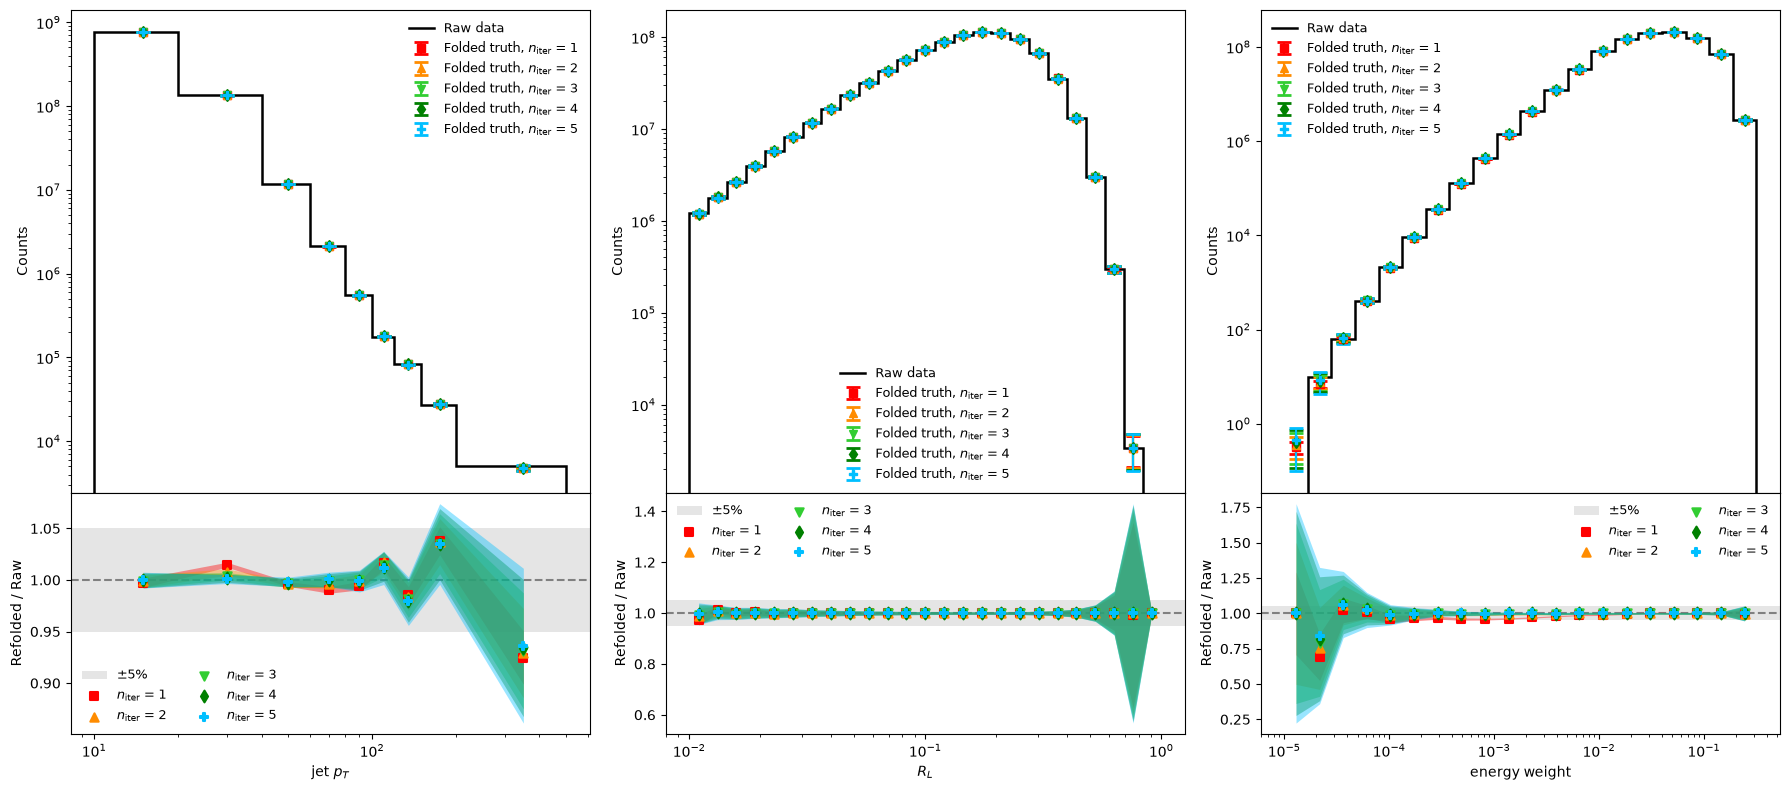

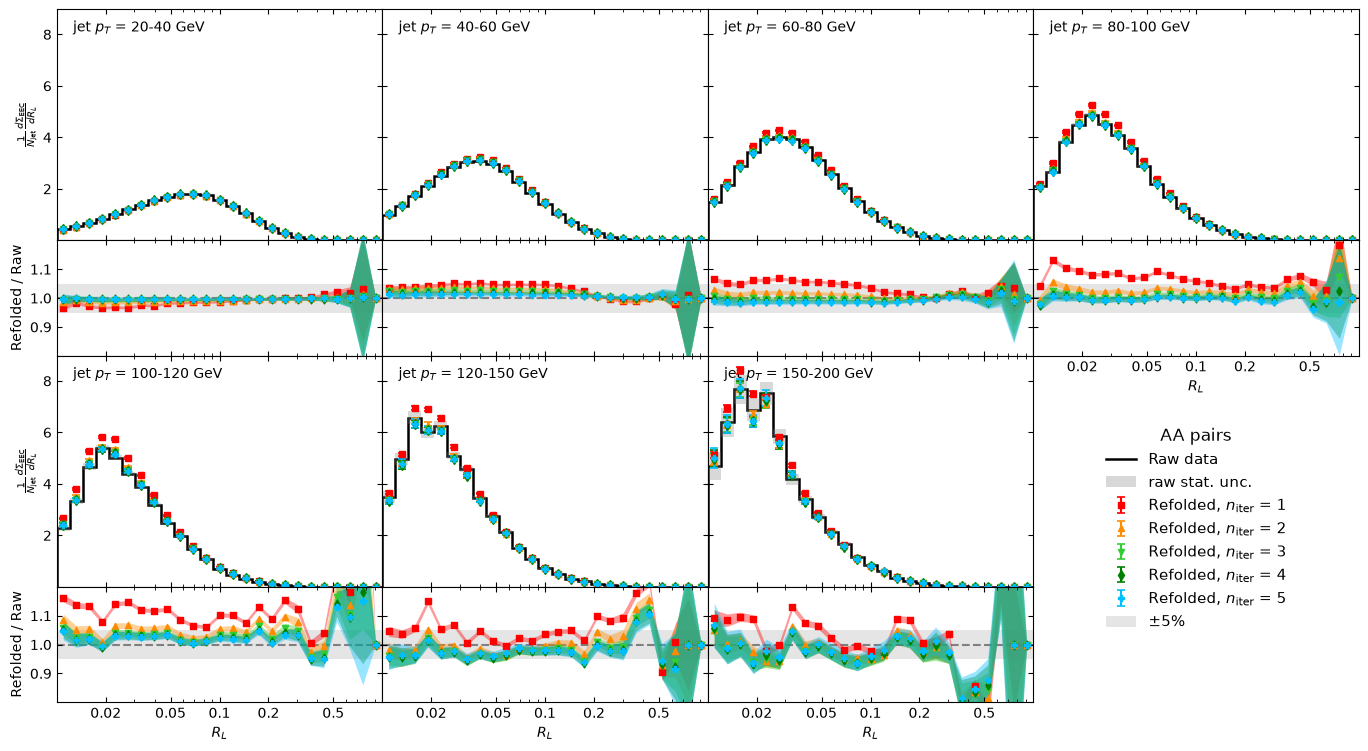

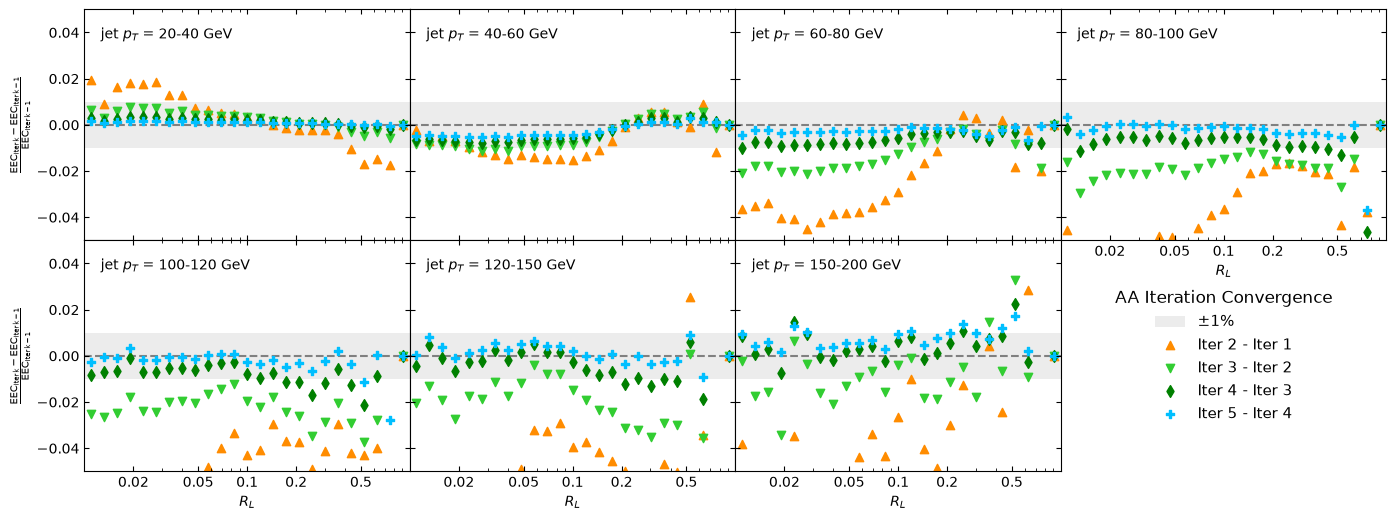

In [66]:
# Data refolding - AA - w/ purity corrections
lab = "AA"
y3_raw, y3_unfolded, y3_unfolded_err, y3_refolded, y3_refolded_err = get_yvals_for_label(lab)
plot_closure_test_axes_singleplot(n_iter, bincenters, binning, binwidths, y3_raw, y3_refolded, y3_refolded_err, L_colors, L_markers, "Raw data", "Folded truth", unfolding=False)

fig = plot_closure_test_fullEEC(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded, bincenters, binning, binwidths, L_colors, L_markers)

fig_delta = plot_refolding_iteration_deltas(lab, h3_refolded[lab], h1_refolded, bincenters, binning, binwidths, L_colors, L_markers)


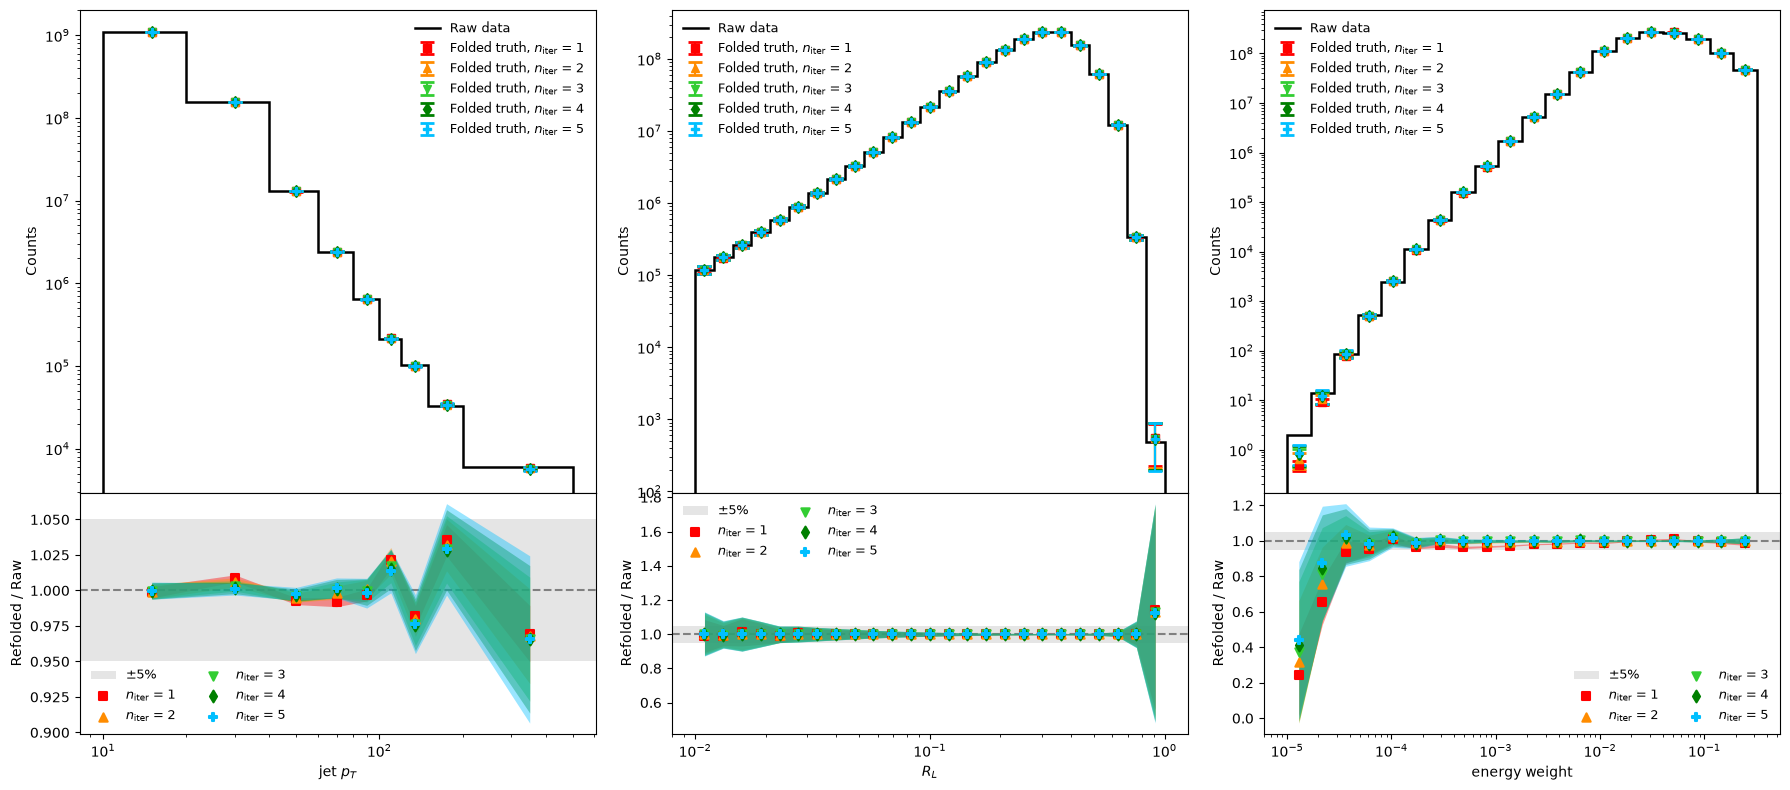

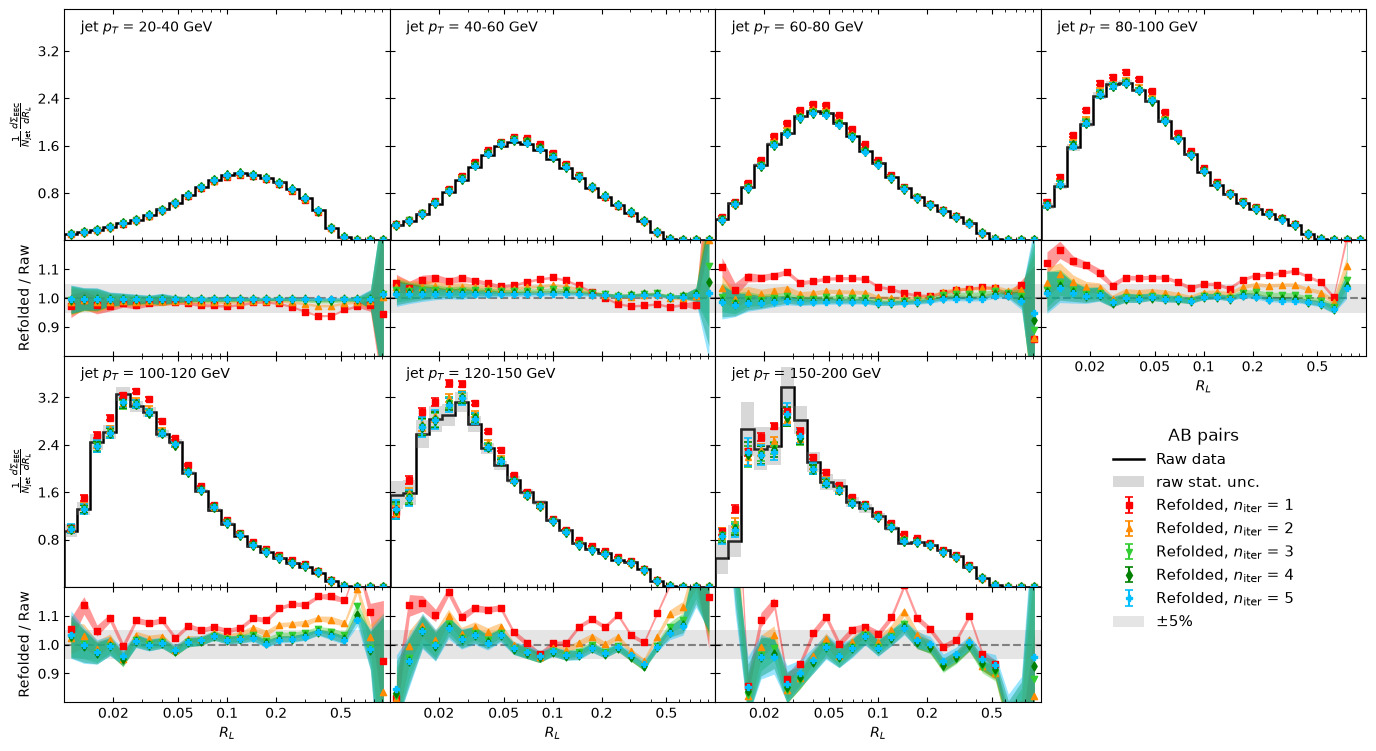

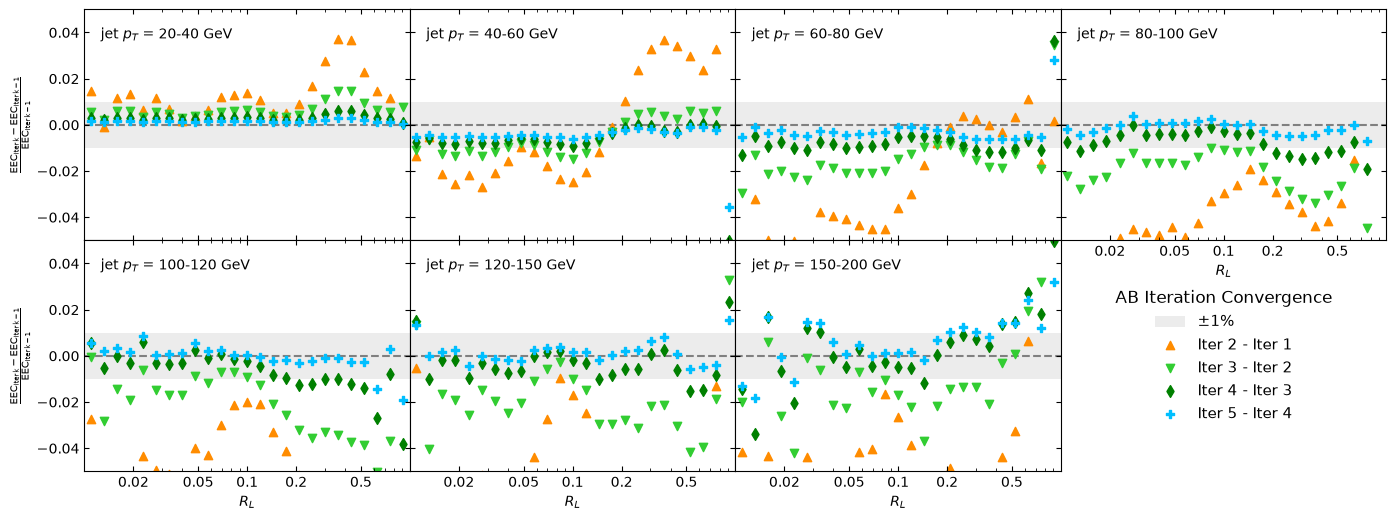

In [67]:
# Data refolding - AA - w/ purity corrections
lab = "AB"
y3_raw, y3_unfolded, y3_unfolded_err, y3_refolded, y3_refolded_err = get_yvals_for_label(lab)
plot_closure_test_axes_singleplot(n_iter, bincenters, binning, binwidths, y3_raw, y3_refolded, y3_refolded_err, L_colors, L_markers, "Raw data", "Folded truth", unfolding=False)

fig = plot_closure_test_fullEEC(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded, bincenters, binning, binwidths, L_colors, L_markers)

fig_delta = plot_refolding_iteration_deltas(lab, h3_refolded[lab], h1_refolded, bincenters, binning, binwidths, L_colors, L_markers)



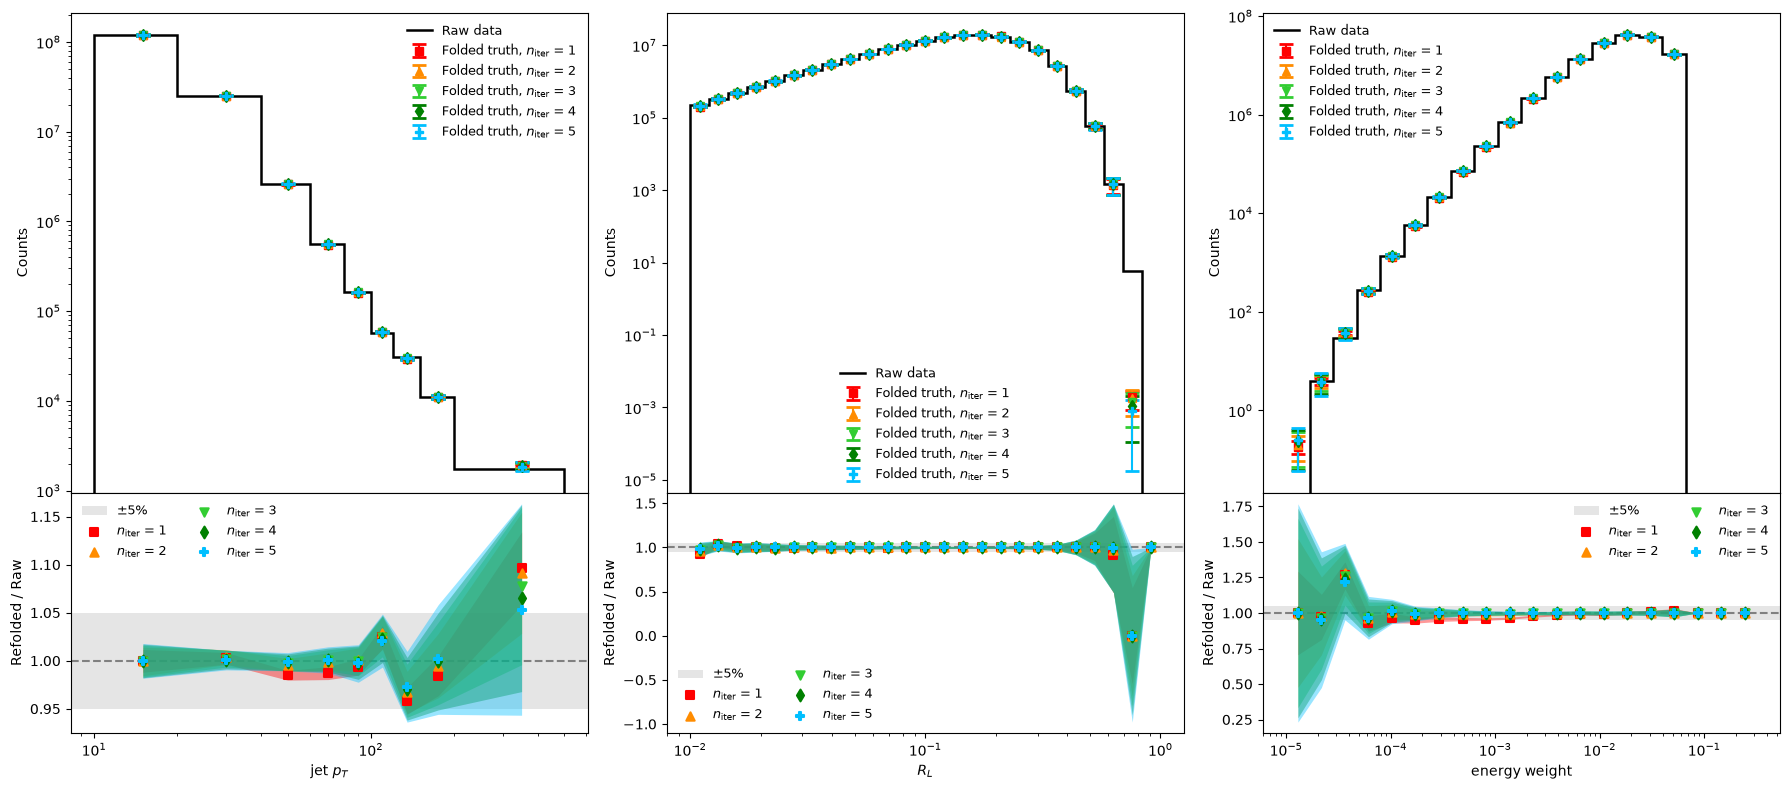

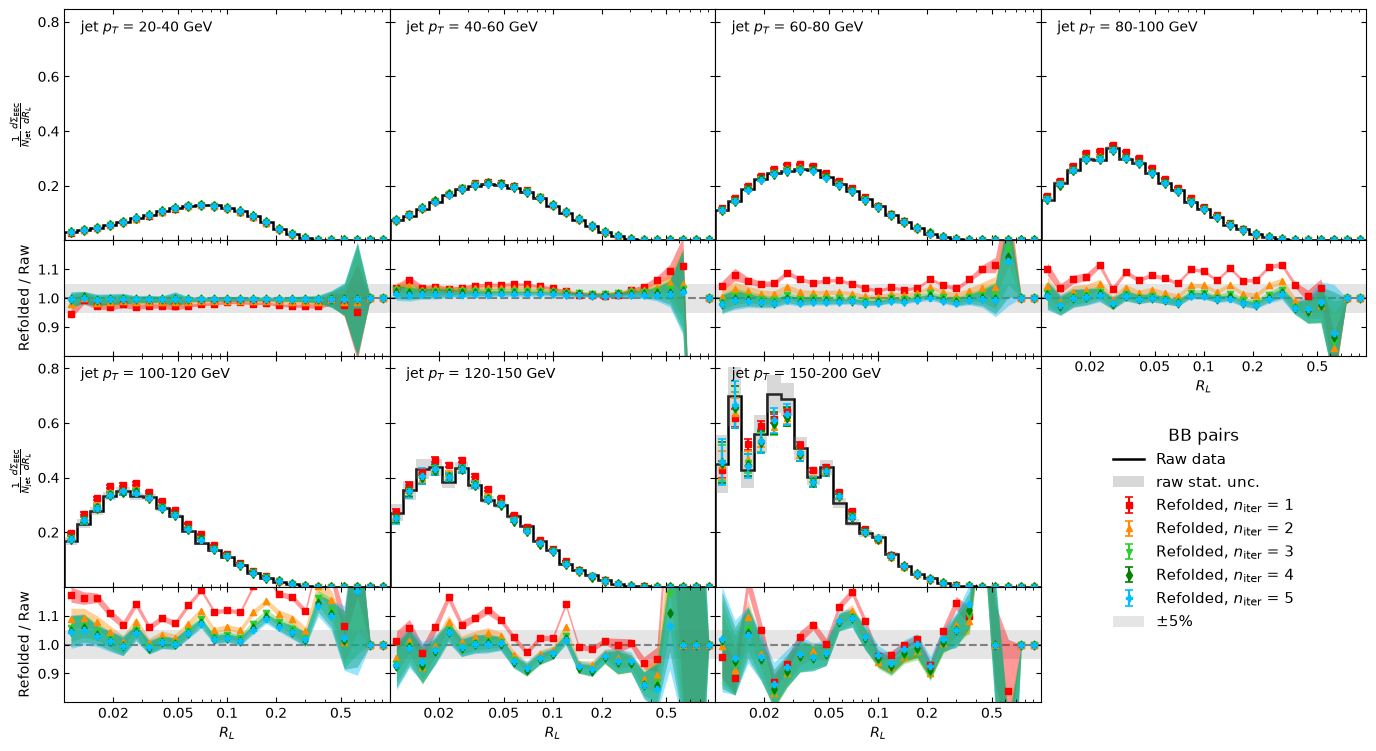

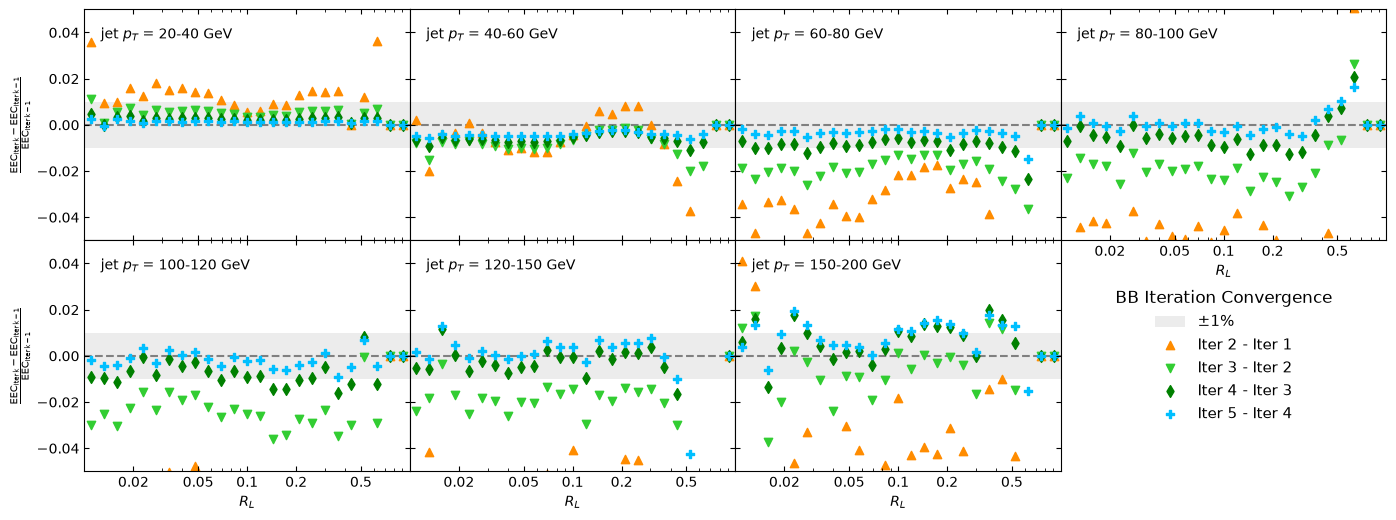

In [68]:
# Data refolding - AA - w/ purity corrections
lab = "BB"
y3_raw, y3_unfolded, y3_unfolded_err, y3_refolded, y3_refolded_err = get_yvals_for_label(lab)
plot_closure_test_axes_singleplot(n_iter, bincenters, binning, binwidths, y3_raw, y3_refolded, y3_refolded_err, L_colors, L_markers, "Raw data", "Folded truth", unfolding=False)

fig = plot_closure_test_fullEEC(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded, bincenters, binning, binwidths, L_colors, L_markers)

fig_delta = plot_refolding_iteration_deltas(lab, h3_refolded[lab], h1_refolded, bincenters, binning, binwidths, L_colors, L_markers)



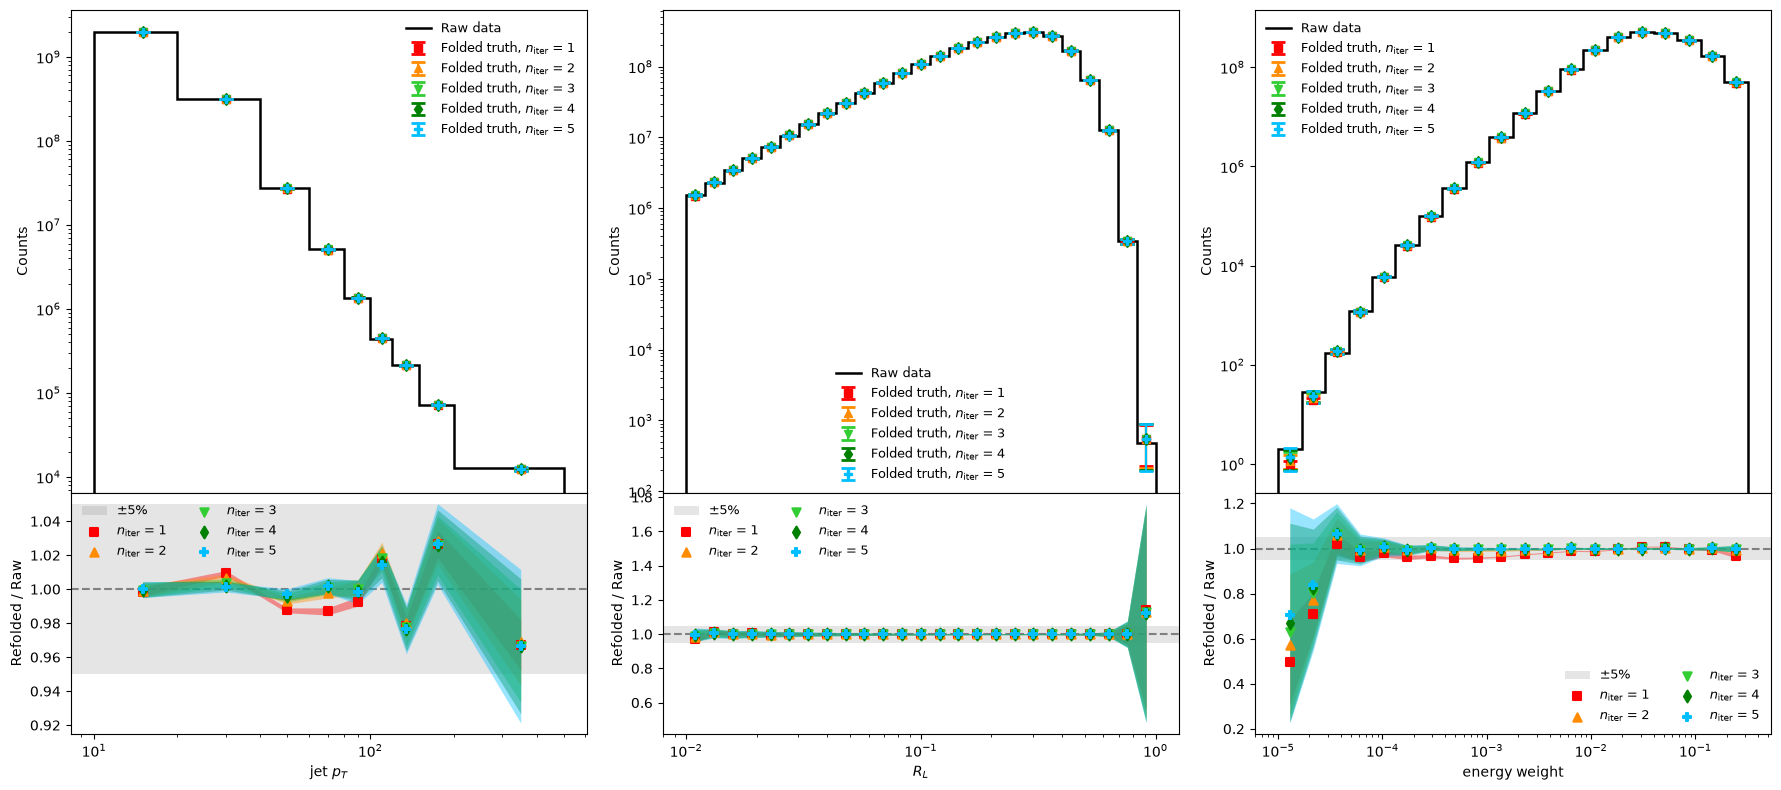

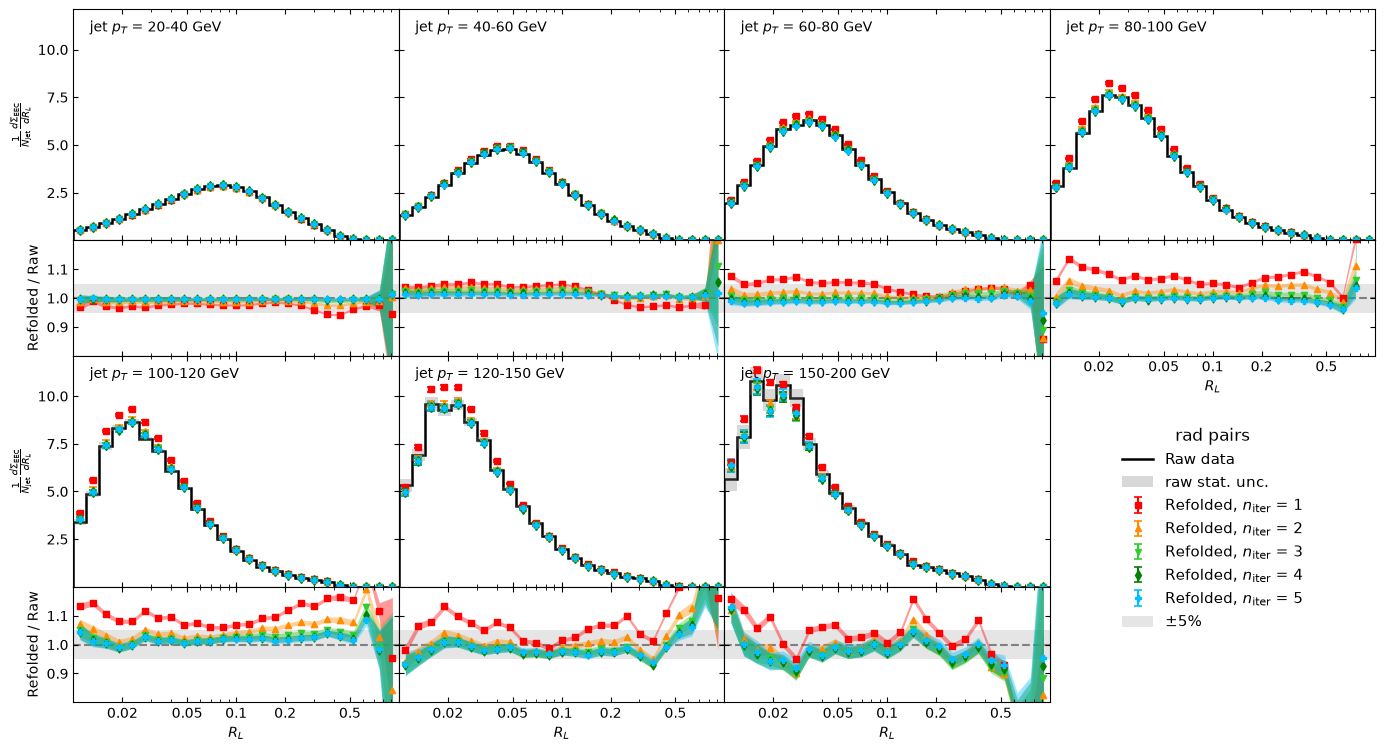

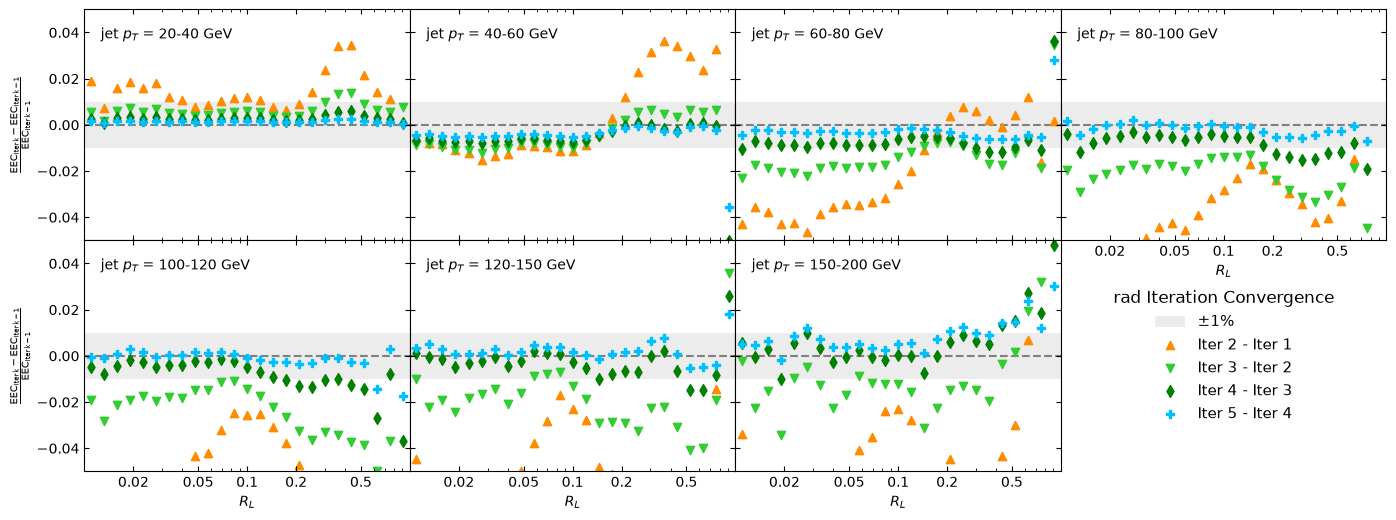

In [69]:
# Data refolding - AA - w/ purity corrections
lab = "rad"
y3_raw, y3_unfolded, y3_unfolded_err, y3_refolded, y3_refolded_err = get_yvals_for_label(lab)
plot_closure_test_axes_singleplot(n_iter, bincenters, binning, binwidths, y3_raw, y3_refolded, y3_refolded_err, L_colors, L_markers, "Raw data", "Folded truth", unfolding=False)

fig = plot_closure_test_fullEEC(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded, bincenters, binning, binwidths, L_colors, L_markers)

fig_delta = plot_refolding_iteration_deltas(lab, h3_refolded[lab], h1_refolded, bincenters, binning, binwidths, L_colors, L_markers)


In [ ]:
############################## UNFOLDED DISTRIBUTIONS ############################
# individual distros

for iteration in range(1):
    fig, axes = plt.subplots(2, 3, figsize=(15,8))

    # ROW 1: raw distributions
    for i in range(3):
        ax = axes[0, i]

        _,_,_=ax.hist(binning_reco[i][:-1], binning_reco[i], weights=theta0_S[i],color='blue', histtype="step", alpha=1, label="MC, reco")
        print(theta0_S[i])
        _,_,_=ax.hist(binning_reco[i][:-1], binning_reco[i], weights=theta_unknown_S[i],color='orange',histtype="step",linestyle='--',alpha=1,label="Data, reco")

        _,_,_=ax.hist(binning[i][:-1], binning[i], weights=theta0_G[i],color='blue', alpha=0.5, label="MC, true")
        _,_,_=ax.hist(binning[i][:-1], binning[i], weights=theta_unknown_G[i],color='orange',alpha=0.5,label="Data, true")
        _,_,_=ax.hist(binning[i][:-1], binning[i],weights=theta_unfolded[iteration][i],color='black',histtype="step",label="RooUnfolded",lw=1)

        ax.errorbar(bincenters[i], theta0_G[i], yerr=theta0_G_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='blue')
        ax.errorbar(bincenters[i], theta_unknown_G[i], yerr=theta_unknown_G_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='orange')
        ax.errorbar(bincenters[i], theta_unfolded[iteration][i], yerr=theta_unfolded_err[iteration][i], capsize=5, capthick=2, fmt='o', linestyle="None", color='black')
        
        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("Counts")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
            ax.set_yscale('log')
            #ax.set_ylim([0.1, 4E8])
    
    # ROW 2: residual plots
    for i in range(3):
        ax = axes[1, i]
        
        yvals, yerrs = get_ratio_safe(theta_unfolded[iteration][i], theta_unknown_G[i], \
                                      numerr=theta_unfolded_err[iteration][i], denomerr=theta_unknown_G_err[i])
        
        ax.step(binning[i], np.insert(yvals, 0, yvals[0]), where="pre",color='red',label="RooUnfolded / true",lw=1)
        ax.errorbar(bincenters[i], yvals, yerr=yerrs, capsize=5, capthick=2, fmt='o', linestyle="None", color='red')

        ax.hlines(y=1, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

        ax.set_xlabel(labels[i])
        ax.set_ylabel("relative error")
        ax.legend(frameon=False)
        
        if i in [0, 1]:
            ax.set_xscale('log')
            ax.set_ylim([0.9, 1.1])
        else:
            ax.set_ylim([0.9, 1.1])

    
    fig.tight_layout()
    # fig.savefig("post_training_" + str(iteration) + ".png")
    # fig.show()
    # plt.close()
plt.show()

In [ ]:
############################## UNFOLDED DISTRIBUTIONS ############################
# individual distros

it = 3

fig, axes = plt.subplots(4, 3, figsize=(16,16))

# ROW 1: raw distributions
for i in range(3):
    ax = axes[0, i]

    if i == 0:
        ax.plot(bincenters[i][:-1], theta_unknown_G[i][:-1], color='black',label="MC true")
    else:
        ax.plot(bincenters[i], theta_unknown_G[i], color='black',label="MC true")

    for iteration in range(it):
        ax.scatter(bincenters[i], theta_unfolded[iteration][i],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("Counts")

        #ax.errorbar(bincenters[i], theta_unfolded[iteration][i], yerr=theta_unfolded_err[iteration][i], capsize=5, capthick=2, fmt='o', linestyle="None", color=L_colors[iteration])
        
        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_yscale('log')
            #ax.set_ylim([0.1, 4E8])
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])

# ROW 2: error wrt Data, true
for i in range(3):
    ax = axes[1, i]

    for iteration in range(1,it):

        yvals, yerrs = get_ratio_safe(theta_unfolded[iteration][i], theta_unknown_G[i], \
                                      numerr=theta_unfolded_err[iteration][i], denomerr=theta_unknown_G_err[i])
        yvals = yvals - 1

        ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        if i == 0:
            ax.fill_between(bincenters[i][:-1], (yvals-yerrs)[:-1], (yvals+yerrs)[:-1], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)
        else:
            ax.fill_between(bincenters[i], yvals-yerrs, yvals+yerrs, alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)

        ax.hlines(y=0, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("EEC relative error wrt Data, true")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_ylim([-0.2, 0.2])
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


# ROW 3: convergence plot (n / n - 1)
for i in range(3):
    ax = axes[2, i]

    for iteration in range(1,it):
    
        yvals = safe_divide(theta_unfolded[iteration][i] , theta_unfolded[iteration-1][i], filler=1)
        ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("n / (n-1)")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_ylim([0.9, 1.1])
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


# ROW 4: statistical error %
for i in range(3):
    ax = axes[3, i]

    for iteration in range(it):
        
        yvals = safe_divide(theta_unfolded_err[iteration][i], theta_unfolded[iteration][i])
        ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("relative unfolding uncertainty")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


fig.tight_layout()
plt.show()

In [ ]:
############################## UNFOLDED DISTRIBUTIONS ############################
# EEC distros

it = 3

fig, axes = plt.subplots(2, 3, figsize=(15,8))

# EEC weight calculation:
# w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

true_EEC = np.array([np.dot(col, bincenters[0]) for col in U_true])
#true_EEC_err = np.array([np.dot(col, bincenters[0]) for col in U_true_err])

unfolded_EEC = np.array([[np.dot(col, bincenters[0]) for col in U_unfolded[iteration]] for iteration in range(len(theta_unfolded))])
unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err[iteration]] for iteration in range(len(theta_unfolded))])

# COL 1: raw EEC distribution WITH relative error over data, true underneath
ax = axes[0, 0]

rl_lims = ax.set_xlim([binning[1][0], binning[1][len(binning[1])-1]])

ax.plot(bincenters[1], true_EEC, color='black',label="Data, true")

for iteration in range(it):

    ax.scatter(bincenters[1], unfolded_EEC[iteration],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
    ax.set_ylabel("EEC")
    
    ax.set_title("EEC")
    ax.set_xlabel(labels[1])

    ax.legend(frameon=False)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(rl_lims)

# row below with the error

ax = axes[1, 0]

ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

for iteration in range(it):

    yvals, yerrs = get_ratio_safe(unfolded_EEC[iteration], true_EEC, \
                                      numerr=unfolded_EEC_err[iteration], denomerr=np.zeros_like(unfolded_EEC[iteration]), filler=1)
    yvals = yvals - 1

    ax.scatter(bincenters[1][1:], yvals[1:], color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.fill_between(bincenters[1][1:], (yvals-yerrs)[1:], (yvals+yerrs)[1:], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)

    ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')
    

    ax.set_title("relative error")
    ax.set_xlabel(labels[1])
    ax.set_ylabel("EEC relative error wrt Data, true")

    ax.set_xscale('log')
    ax.set_ylim([-0.5, 0.5])
    ax.set_xlim(rl_lims)


# COL 2: convergence plot (n / n - 1)
ax = axes[0, 1]

for iteration in range(1,it):

    yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
    ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

    ax.set_title("EEC")
    ax.set_xlabel(labels[1])
    ax.set_ylabel("n / (n-1)")
    ax.legend(frameon=False)

    ax.set_xscale('log')
    ax.set_ylim([0.85, 1.15])
    ax.set_xlim(rl_lims)


# COL 3: statistical error %
ax = axes[0, 2]

for iteration in range(it):
    
    yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
    ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.set_title("EEC")
    ax.set_xlabel(labels[1])
    ax.set_ylabel("unfolding uncertainty %")
    ax.legend(frameon=False)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(rl_lims)


fig.tight_layout()
plt.show()


In [ ]:
################# WENQINGS MC RECO/TRUE RATIOS #################

f_compare = ur.open("./pythiaMC_corr_hists.root")

pythia_names = ["Ratio_hJetE2C_norm_ch_jetR4_2040_trk10", "Ratio_hJetE2C_norm_ch_jetR4_4060_trk10", "Ratio_hJetE2C_norm_ch_jetR4_6080_trk10"]
h1_EEC_ratios = [f_compare[name].values() for name in pythia_names]

print(h1_EEC_ratios)

R_bins_compare = f_compare["Ratio_hJetE2C_norm_ch_jetR4_2040_trk10"].axis("x").edges()
R_bincenters_compare = get_log_bincenters(R_bins_compare)


In [ ]:
N_jets_unf = [7.91905502e+04, 4.07895819e+03, 5.64378641e+02]
N_jets_unf_err = [3.07052137e+02, 6.42184893e+01, 2.37848329e+01]
N_jets_true = [7.92135529e+04, 4.07969140e+03, 5.64283433e+02]
N_jets_raw = [5.46348066e+04, 2.53230942e+03, 3.17720949e+02]

In [ ]:
############################## UNFOLDED DISTRIBUTIONS ############################
############################## ( with pT cut applied ) ###########################

# EEC distros

it = 3

j = 0
for i in range(2, 5):

    fig, axes = plt.subplots(1, 4, figsize=(20,4))

    ptcut_bins = [i, i+1]
    slice_on_pt = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    ptcut_bins_reco = [i-1, i]
    slice_on_pt_reco = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    U_true_cut = slice_on_pt(h3_true.values()) #  * h3_purity.values())
    U_true_err_cut = slice_on_pt(h3_true.errors())

    U_unfolded_cut = [slice_on_pt(A.values()) for A in h3_unfolded]
    U_unfolded_err_cut = [slice_on_pt(A.errors()) for A in h3_unfolded]

    # EEC weight calculation:
    # w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

    true_EEC = np.array([np.dot(col, bincenters[0]) for col in U_true_cut]) / N_jets_true[j]
    true_EEC_err = np.array([np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_true_err_cut]) / N_jets_true[j]

    unfolded_EEC = np.array([[np.dot(col, bincenters[0]) for col in U_unfolded_cut[iteration]] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err_cut[iteration]] for iteration in range(len(theta_unfolded))])

    # divide by number of jets, and propagate error in number of unfolded jets
    unfolded_EEC_err = np.array([get_ratio_err(unfolded_EEC[iteration], N_jets_unf[j], unfolded_EEC_err[iteration], N_jets_unf_err[j]) for iteration in range(len(theta_unfolded))])
    unfolded_EEC /= N_jets_unf[j]

    #unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err[iteration]] for iteration in range(len(theta_unfolded))]) / N_jets_unf[j]

    # COL 1: raw EEC distribution WITH relative error over data, true underneath
    ax = axes[0]

    rl_lims = ax.set_xlim([binning[1][0], binning[1][len(binning[1])-1]])

    # various comparison EEC plots

    # Data, true, unbinned in energy weight (is the actaul truth)
    # should be close to RM binning when energy weight granulatrity is ok, also used to check definition of energy weight log bin center
    # apply purity correction too
    true_eec_unbinned = yslice(h2_true_eec.values(), ptcut_bins[0], ptcut_bins[1]) / N_jets_true[j]
    true_eec_unbinned_err = yslice(h2_true_eec.errors(), ptcut_bins[0], ptcut_bins[1]) / N_jets_true[j]
    ax.plot(bincenters[1], true_eec_unbinned, color='black', alpha=0.6, linestyle='dashed', label="Data, true, unbinned")

    # Data, raw, unbinned in energy weight
    raw_eec_unbinned = yslice(h2_raw_eec.values(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / N_jets_raw[j]
    raw_eec_unbinned_err = yslice(h2_raw_eec.errors(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / N_jets_raw[j]
    ax.plot(bincenters[1], raw_eec_unbinned, color='red', alpha=0.6, linestyle='dashed', label="Data, raw, unbinned")

    # Data, true, RM binning with binnings from the response matrix (i.e. calculated with some binned energy weight)
    ax.plot(bincenters[1], true_EEC, color='blue', alpha=0.6, label="Data, true, RM binning")

    #print(true_eec_unbinned / raw_eec_unbinned)

    for iteration in range(it):

        ax.scatter(bincenters[1], unfolded_EEC[iteration],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("EEC")
        
        ax.set_title("EEC")
        ax.set_xlabel(labels[1])

        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    # row below with the error

    ax = axes[1]

    ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='blue', linestyle='solid')

    # compare with Wenqing's reco / true ratios
    ax.plot(R_bincenters_compare, h1_EEC_ratios[j] - 1, color='green', alpha=0.6, label="Wenqing's MC reco / true")

    yvals, yerrs = get_ratio_safe(true_eec_unbinned, true_EEC, \
                                        numerr=true_EEC_err, denomerr=true_eec_unbinned_err, filler=1)
    yvals = yvals - 1
    #ax.plot(bincenters[1], yvals, color='black',linestyle='dashed', alpha=0.6, label="Data, true, unbinned")

    yvals, yerrs = get_ratio_safe(raw_eec_unbinned, true_EEC, \
                                        numerr=raw_eec_unbinned, denomerr=true_eec_unbinned_err, filler=1)
    yvals = yvals - 1
    ax.plot(bincenters[1], yvals, color='red', alpha=0.6, linestyle='dashed', label="my reco, unbinned / true")

    for iteration in range(it):

        yvals, yerrs = get_ratio_safe(unfolded_EEC[iteration], true_EEC, \
                                        numerr=unfolded_EEC_err[iteration], denomerr=true_EEC_err, filler=1)
        yvals = yvals - 1

        ax.scatter(bincenters[1][1:], yvals[1:], color=L_colors[iteration],marker=L_markers[iteration],lw=1)

        ax.fill_between(bincenters[1][1:], (yvals-yerrs)[1:], (yvals+yerrs)[1:], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)
        
        ax.legend(frameon=False)
        ax.set_title("relative error")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("EEC relative error wrt Data, true, RM binning")

        ax.set_xscale('log')
        ax.set_ylim([-0.3, 0.3])
        ax.set_xlim(rl_lims)


    # COL 2: convergence plot (n / n - 1)
    ax = axes[2]

    for iteration in range(1,it):

        yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("n / (n-1)")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_ylim([0.85, 1.15])
        ax.set_xlim(rl_lims)


    # COL 3: statistical error %
    ax = axes[3]

    for iteration in range(it):
        
        yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("relative unfolding uncertainty")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)


    fig.tight_layout()
    plt.show()

    j += 1


In [ ]:
############################## UNFOLDED DISTRIBUTIONS ############################
############################## ( with pT cut applied ) ###########################

# EEC distros

it = 3

fig, axes = plt.subplots(3, 4, figsize=(20,12))

j = 0
for i in range(2, 5):    

    ptcut_bins = [i, i+1]
    slice_on_pt = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    ptcut_bins_reco = [i-1, i]
    slice_on_pt_reco = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    U_true_cut = slice_on_pt(h3_true.values()) #  * h3_purity.values())
    U_true_err_cut = slice_on_pt(h3_true.errors())

    U_unfolded_cut = [slice_on_pt(A.values()) for A in h3_unfolded]
    U_unfolded_err_cut = [slice_on_pt(A.errors()) for A in h3_unfolded]

    ###############################  EEC and error CALCULATION  ###############################
    # EEC weight calculation:
    # w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

    true_EEC = np.array([np.dot(col, bincenters[0]) for col in U_true_cut]) / (N_jets_true[j] * binwidths[1])
    true_EEC_err = np.array([np.sqrt(np.dot(col, np.array(bincenters[0])**2)) for col in U_true_err_cut]) / (N_jets_true[j] * binwidths[1])

    unfolded_EEC = np.array([ np.array( [np.dot(col, bincenters[0]) for col in U_unfolded_cut[iteration]] ) / binwidths[1] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.array([np.array([np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err_cut[iteration]]) / binwidths[1] for iteration in range(len(theta_unfolded))])

    # add on statistical uncertainty, sum in quadrature
    stat_err = np.array([ np.array( [np.sqrt(np.dot(col, np.array(bincenters[0])**2)) for col in U_unfolded_cut[iteration]] ) / binwidths[1] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.sqrt(unfolded_EEC_err**2 + stat_err**2)

    # divide by number of jets, and propagate error in number of unfolded jets
    unfolded_EEC_err = np.array([get_ratio_err(unfolded_EEC[iteration], N_jets_unf[j], unfolded_EEC_err[iteration], N_jets_unf_err[j]) for iteration in range(len(theta_unfolded))])
    unfolded_EEC /= N_jets_unf[j]

    ##################################

    # COL 1: raw EEC distribution WITH relative error over data, true underneath
    ax = axes[j, 0]

    rl_lims = ax.set_xlim([1E-2, 1])

    # various comparison EEC plots

    # Data, true, unbinned in energy weight (is the actaul truth)
    # should be close to RM binning when energy weight granulatrity is ok, also used to check definition of energy weight log bin center
    # apply purity correction too
    true_eec_unbinned = yslice(h2_true_eec.values(), ptcut_bins[0], ptcut_bins[1]) / (N_jets_true[j] * binwidths[1])
    true_eec_unbinned_err = yslice(h2_true_eec.errors(), ptcut_bins[0], ptcut_bins[1]) / (N_jets_true[j] * binwidths[1])
    ax.plot(bincenters[1], true_eec_unbinned, color='black', alpha=0.6, linestyle='dashed', label="Data, true, unbinned")

    # Data, raw, unbinned in energy weight
    raw_eec_unbinned = yslice(h2_raw_eec.values(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / (N_jets_raw[j] * binwidths[1])
    raw_eec_unbinned_err = yslice(h2_raw_eec.errors(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / (N_jets_raw[j] * binwidths[1])
    ax.plot(bincenters[1], raw_eec_unbinned, color='red', alpha=0.6, linestyle='dashed', label="Data, reco, unbinned")

    # Data, true, RM binning with binnings from the response matrix (i.e. calculated with some binned energy weight)
    ax.plot(bincenters[1], true_EEC, color='blue', alpha=0.6, label="Data, true, RM binning")

    #print(true_eec_unbinned / raw_eec_unbinned)

    for iteration in range(it):

        ax.scatter(bincenters[1], unfolded_EEC[iteration],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("$\\frac{1}{N_{jets}}\\frac{d\Sigma}{dR_L}$", fontsize=14)
        
        ax.set_title("EEC")
        ax.set_xlabel(labels[1])

        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    # row below with the error

    ax = axes[j, 1]

    ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='blue', linestyle='solid')

    yvals, yerrs = get_ratio_safe(true_eec_unbinned, true_EEC, \
                                        numerr=true_eec_unbinned_err, denomerr=true_EEC_err, filler=1)
    yvals = yvals - 1
    ax.plot(bincenters[1], yvals, color='black', alpha=0.6, linestyle='dashed', label="Data, true, unbinned")

    for iteration in range(it):

        yvals, yerrs = get_ratio_safe(unfolded_EEC[iteration], true_EEC, \
                                        numerr=unfolded_EEC_err[iteration], denomerr=true_EEC_err, filler=1)
        yvals = yvals - 1

        ax.scatter(bincenters[1][1:], yvals[1:], color=L_colors[iteration],marker=L_markers[iteration],lw=1, label="n_iter = {}".format(iteration+1))

        ax.fill_between(bincenters[1][1:], (yvals-yerrs)[1:], (yvals+yerrs)[1:], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)
        
        ax.set_ylabel('$\left(\left.\\frac{1}{N_jets}\\frac{d\Sigma}{dR_L} \middle/ \\frac{1}{N_jets}\\frac{d\Sigma_\\text{true}}{dR_L} \\right.\\right) - 1$', fontsize=14)
        
        ax.set_title("relative difference with data, true, RM binning")
        ax.set_xlabel(labels[1])

        ax.set_xscale('log')
        ax.set_ylim([-0.2, 0.2])
        ax.set_xlim(rl_lims)


    # COL 2: convergence plot (n / n - 1)
    ax = axes[j, 2]

    for iteration in range(1,it):

        yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

        ax.set_title("relative difference by iteration")
        ax.set_xlabel(labels[1])
        ax.set_ylabel('$\left.\\frac{1}{N_jets}\\frac{d\Sigma_n}{dR_L} \middle/ \\frac{1}{N_jets}\\frac{d\Sigma_{n-1}}{dR_L} \\right.$', fontsize=14)
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_ylim([0.9, 1.1])
        ax.set_xlim(rl_lims)


    # COL 3: statistical error %
    ax = axes[j, 3]

    for iteration in range(it):
        
        yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title("uncertainty")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("relative uncertainty")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    j += 1

fig.tight_layout()
plt.show()
